In [1]:
import os
import numpy as np
import pandas as pd
import random
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

def load_glove_vectors(glove_file):
    word_vectors = {}
    with open(glove_file, 'r', encoding='utf-8') as f:
        for line in f:
            values = line.split()
            word = values[0]
            vector = np.asarray(values[1:], dtype='float32')
            word_vectors[word] = vector
    return word_vectors

glove_file = 'C:/Users/aznur/Desktop/Projects/nlp_analysis/glove.6B.300d.txt'
glove_word_vectors = load_glove_vectors(glove_file)

In [2]:
energy = pd.read_csv('C:/Users/aznur/Desktop/Projects/data_extraction/Applied Catalysis A/gender_dimensions/most_common_new.csv')
energy = [word for word in energy['Word'] if len(word) > 3]
energy_subset = energy[:15]

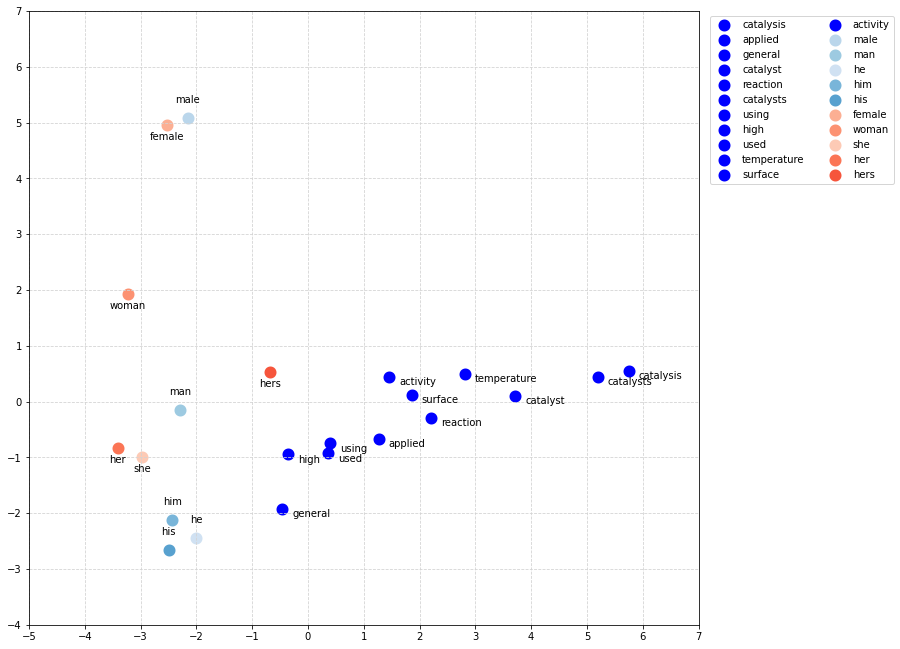

In [3]:
male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

words = energy_subset + male_words + female_words

valid_words = []
valid_dict_words_vector = {}

for word in words:
    if word in glove_word_vectors:
        vector = glove_word_vectors[word]
        valid_words.append(word)
        valid_dict_words_vector[word] = vector

all_values = [valid_dict_words_vector[key] for key in valid_dict_words_vector]
new = pd.DataFrame(all_values, index=valid_words)

pca = PCA(n_components=2)
result = pca.fit_transform(new)

word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)

    if word not in word_colours:
        offset = (10, -8)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in male_words:
        offset = (0, 15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
    if word in female_words:
        offset = (0, -15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
        

plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')
plt.xticks(np.arange(x_min-1, x_max + 1.1, 1))
plt.yticks(np.arange(y_min-1, y_max + 1.1, 1))
plt.xlim(x_min-1, x_max+1)
plt.ylim(y_min-1, y_max+1)
plt.savefig('C:/Users/aznur/Desktop/Projects/data_extraction/Applied Catalysis A/gender_dimensions/words_pretrained_glove.png', bbox_inches='tight')
plt.show()

In [4]:
from scipy.spatial.distance import cosine

def average_cosine_distance(target_vector, vectors_list):
    return np.mean([cosine(target_vector, vec) for vec in vectors_list])

male_averages = []
female_averages = []

energy_vectors = [valid_dict_words_vector[word] for word in energy_subset]

for word in energy_subset:
    word_vector = valid_dict_words_vector[word]

    male_distances = [average_cosine_distance(word_vector, [valid_dict_words_vector[m_word] for m_word in male_words])]
    female_distances = [average_cosine_distance(word_vector, [valid_dict_words_vector[f_word] for f_word in female_words])]

    male_averages.append(np.mean(male_distances))
    female_averages.append(np.mean(female_distances))

print(f"Overall average cosine distance to male pronouns for energy words: {np.mean(male_averages):.4f}")
print(f"Overall average cosine distance to female pronouns for energy words: {np.mean(female_averages):.4f}")

Overall average cosine distance to male pronouns for energy words: 0.8577
Overall average cosine distance to female pronouns for energy words: 0.9118


In [5]:
energy = pd.read_csv('C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Greenhouse Gas Control/gender_dimensions/most_common_new.csv')
energy = [word for word in energy['Word'] if len(word) > 3]
energy_subset = energy[:15]

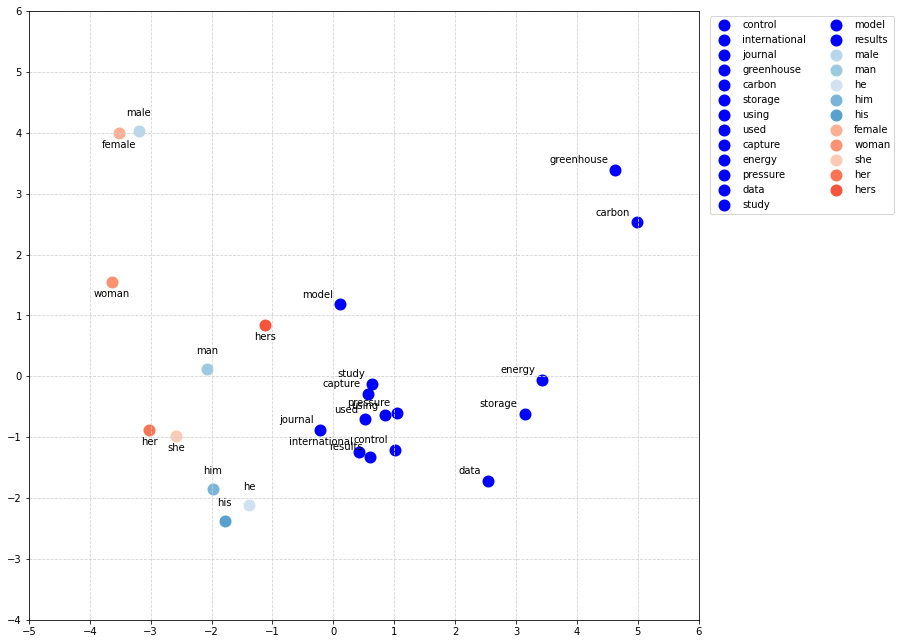

In [6]:
male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

words = energy_subset + male_words + female_words

valid_words = []
valid_dict_words_vector = {}

for word in words:
    if word in glove_word_vectors:
        vector = glove_word_vectors[word]
        valid_words.append(word)
        valid_dict_words_vector[word] = vector

all_values = [valid_dict_words_vector[key] for key in valid_dict_words_vector]
new = pd.DataFrame(all_values, index=valid_words)

pca = PCA(n_components=2)
result = pca.fit_transform(new)

word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)

    if word not in word_colours:
        offset = (-7, 7)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='right', fontsize=10, color='black')
    if word in male_words:
        offset = (0, 15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
    if word in female_words:
        offset = (0, -15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
        
plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')
plt.xticks(np.arange(x_min-1, x_max + 1.1, 1))
plt.yticks(np.arange(y_min-1, y_max + 1.1, 1))
plt.xlim(x_min-1, x_max+1)
plt.ylim(y_min-1, y_max+1)
plt.savefig('C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Greenhouse Gas Control/gender_dimensions/words_pretrained_glove.png', bbox_inches='tight')
plt.show()

In [7]:
male_averages = []
female_averages = []

energy_vectors = [valid_dict_words_vector[word] for word in energy_subset]

for word in energy_subset:
    word_vector = valid_dict_words_vector[word]

    male_distances = [average_cosine_distance(word_vector, [valid_dict_words_vector[m_word] for m_word in male_words])]
    female_distances = [average_cosine_distance(word_vector, [valid_dict_words_vector[f_word] for f_word in female_words])]

    male_averages.append(np.mean(male_distances))
    female_averages.append(np.mean(female_distances))

print(f"Overall average cosine distance to male pronouns for energy words: {np.mean(male_averages):.4f}")
print(f"Overall average cosine distance to female pronouns for energy words: {np.mean(female_averages):.4f}")

Overall average cosine distance to male pronouns for energy words: 0.8021
Overall average cosine distance to female pronouns for energy words: 0.8617


In [8]:
energy = pd.read_csv('C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Hydrogen Energy/gender_dimensions/most_common_new.csv')
energy = [word for word in energy['Word'] if len(word) > 3]
energy_subset = energy[:15]

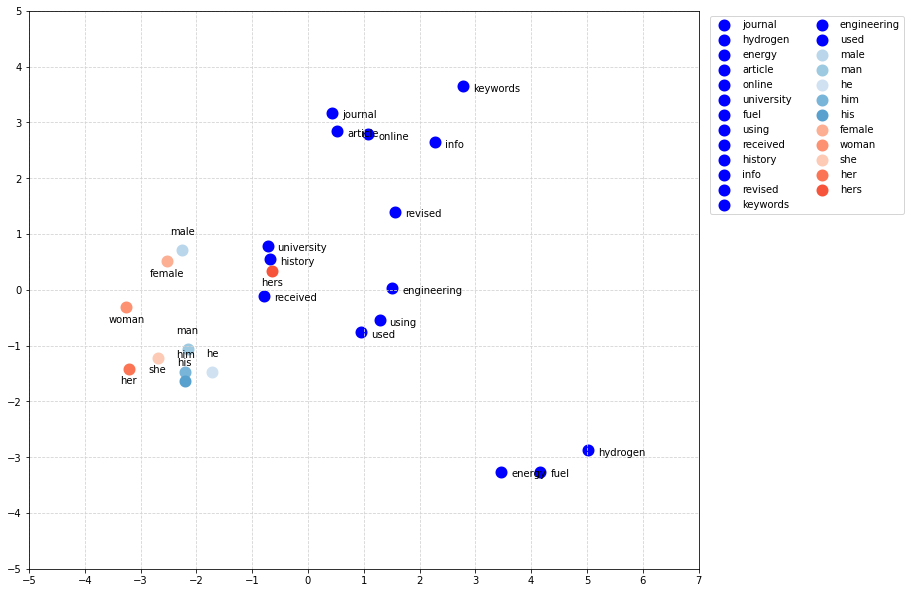

In [9]:
male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

words = energy_subset + male_words + female_words

valid_words = []
valid_dict_words_vector = {}

for word in words:
    if word in glove_word_vectors:
        vector = glove_word_vectors[word]
        valid_words.append(word)
        valid_dict_words_vector[word] = vector

all_values = [valid_dict_words_vector[key] for key in valid_dict_words_vector]
new = pd.DataFrame(all_values, index=valid_words)

pca = PCA(n_components=2)
result = pca.fit_transform(new)

word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)

    if word not in word_colours:
        offset = (10, -5)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in male_words:
        offset = (0, 15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
    if word in female_words:
        offset = (0, -15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
        
plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')
plt.xticks(np.arange(x_min-1, x_max + 1.1, 1))
plt.yticks(np.arange(y_min-1, y_max + 1.1, 1))
plt.xlim(x_min-1, x_max+1)
plt.ylim(y_min-1, y_max+1)
plt.savefig('C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Hydrogen Energy/gender_dimensions/words_pretrained_glove.png', bbox_inches='tight')
plt.show()

In [10]:
male_averages = []
female_averages = []

energy_vectors = [valid_dict_words_vector[word] for word in energy_subset]

for word in energy_subset:
    word_vector = valid_dict_words_vector[word]

    male_distances = [average_cosine_distance(word_vector, [valid_dict_words_vector[m_word] for m_word in male_words])]
    female_distances = [average_cosine_distance(word_vector, [valid_dict_words_vector[f_word] for f_word in female_words])]

    male_averages.append(np.mean(male_distances))
    female_averages.append(np.mean(female_distances))

print(f"Overall average cosine distance to male pronouns for energy words: {np.mean(male_averages):.4f}")
print(f"Overall average cosine distance to female pronouns for energy words: {np.mean(female_averages):.4f}")

Overall average cosine distance to male pronouns for energy words: 0.8370
Overall average cosine distance to female pronouns for energy words: 0.8787


In [11]:
energy = pd.read_csv('C:/Users/aznur/Desktop/Projects/data_extraction/Solar Energy/gender_dimensions/most_common_new.csv')
energy = [word for word in energy['Word'] if len(word) > 3]
energy_subset = energy[:15]

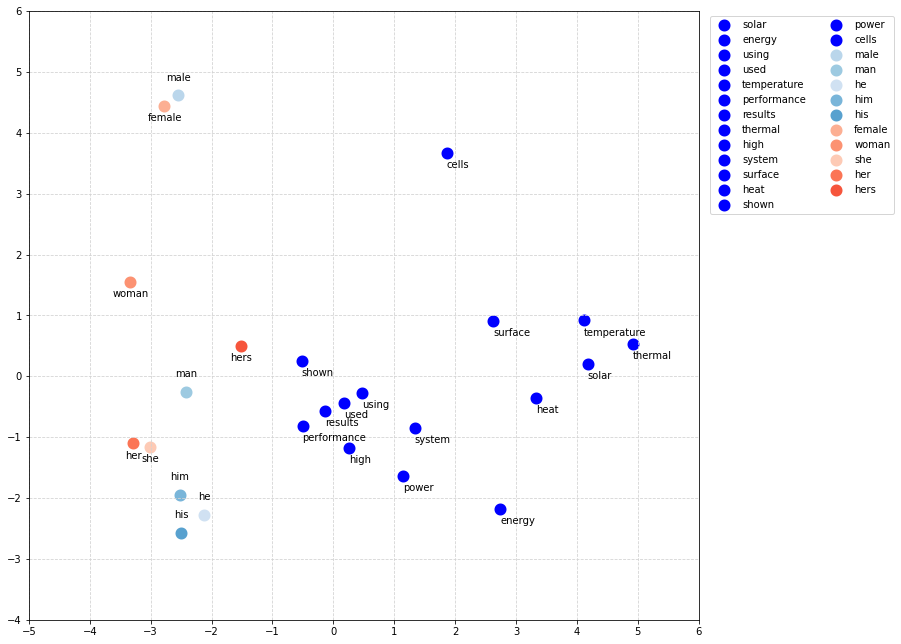

In [12]:
male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

words = energy_subset + male_words + female_words

valid_words = []
valid_dict_words_vector = {}

for word in words:
    if word in glove_word_vectors:
        vector = glove_word_vectors[word]
        valid_words.append(word)
        valid_dict_words_vector[word] = vector

all_values = [valid_dict_words_vector[key] for key in valid_dict_words_vector]
new = pd.DataFrame(all_values, index=valid_words)

pca = PCA(n_components=2)
result = pca.fit_transform(new)

word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)

    if word not in word_colours:
        offset = (0, -15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in male_words:
        offset = (0, 15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
    if word in female_words:
        offset = (0, -15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
        
plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')  # Set equal aspect ratio
plt.xticks(np.arange(x_min-1, x_max + 1.1, 1))
plt.yticks(np.arange(y_min-1, y_max + 1.1, 1))
plt.xlim(x_min-1, x_max+1)
plt.ylim(y_min-1, y_max+1)
plt.savefig('C:/Users/aznur/Desktop/Projects/data_extraction/Solar Energy/gender_dimensions/words_pretrained_glove.png', bbox_inches='tight')
plt.show()

In [13]:
male_averages = []
female_averages = []

energy_vectors = [valid_dict_words_vector[word] for word in energy_subset]

for word in energy_subset:
    word_vector = valid_dict_words_vector[word]

    male_distances = [average_cosine_distance(word_vector, [valid_dict_words_vector[m_word] for m_word in male_words])]
    female_distances = [average_cosine_distance(word_vector, [valid_dict_words_vector[f_word] for f_word in female_words])]

    male_averages.append(np.mean(male_distances))
    female_averages.append(np.mean(female_distances))

print(f"Overall average cosine distance to male pronouns for energy words: {np.mean(male_averages):.4f}")
print(f"Overall average cosine distance to female pronouns for energy words: {np.mean(female_averages):.4f}")

Overall average cosine distance to male pronouns for energy words: 0.7995
Overall average cosine distance to female pronouns for energy words: 0.8554


In [14]:
energy = pd.read_csv('C:/Users/aznur/Desktop/Projects/data_extraction/Transport in Porous Media/gender_dimensions/most_common_new.csv')
energy = [word for word in energy['Word'] if len(word) > 3]
energy_subset = energy[:15]

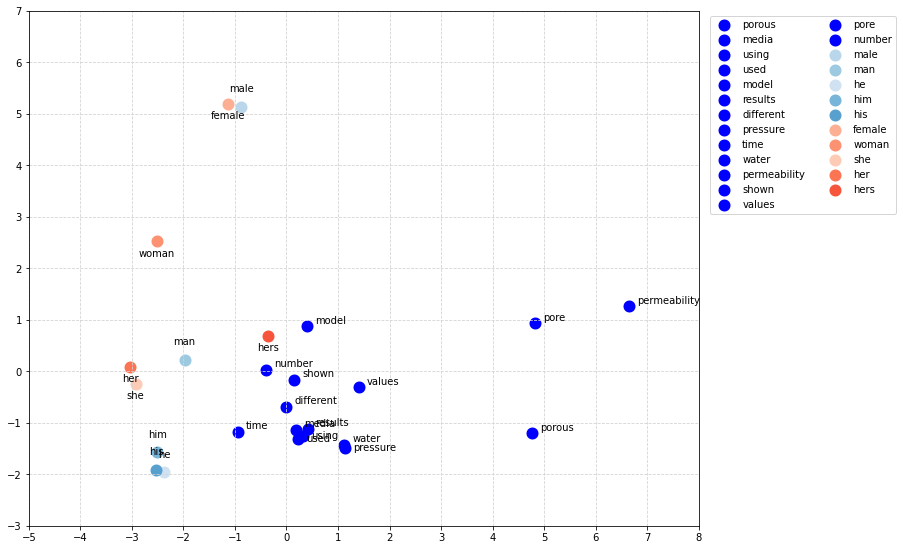

In [15]:
male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

words = energy_subset + male_words + female_words

valid_words = []
valid_dict_words_vector = {}

for word in words:
    if word in glove_word_vectors:
        vector = glove_word_vectors[word]
        valid_words.append(word)
        valid_dict_words_vector[word] = vector

all_values = [valid_dict_words_vector[key] for key in valid_dict_words_vector]
new = pd.DataFrame(all_values, index=valid_words)

pca = PCA(n_components=2)
result = pca.fit_transform(new)

word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)

    if word not in word_colours:
        if word == 'pressure' or word == 'used' or word == 'using':
            offset = (8, -3)
            plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
        else:
            offset = (8, 3)
            plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in male_words:
        offset = (0, 15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
    if word in female_words:
        offset = (0, -15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
        
plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')
plt.xticks(np.arange(x_min-1, x_max + 1.1, 1))
plt.yticks(np.arange(y_min-1, y_max + 1.1, 1))
plt.xlim(x_min-1, x_max+1)
plt.ylim(y_min-1, y_max+1)
plt.savefig('C:/Users/aznur/Desktop/Projects/data_extraction/Transport in Porous Media/gender_dimensions/words_pretrained_glove.png', bbox_inches='tight')
plt.show()

In [16]:
male_averages = []
female_averages = []

energy_vectors = [valid_dict_words_vector[word] for word in energy_subset]

for word in energy_subset:
    word_vector = valid_dict_words_vector[word]

    male_distances = [average_cosine_distance(word_vector, [valid_dict_words_vector[m_word] for m_word in male_words])]
    female_distances = [average_cosine_distance(word_vector, [valid_dict_words_vector[f_word] for f_word in female_words])]

    male_averages.append(np.mean(male_distances))
    female_averages.append(np.mean(female_distances))

print(f"Overall average cosine distance to male pronouns for energy words: {np.mean(male_averages):.4f}")
print(f"Overall average cosine distance to female pronouns for energy words: {np.mean(female_averages):.4f}")

Overall average cosine distance to male pronouns for energy words: 0.7972
Overall average cosine distance to female pronouns for energy words: 0.8416
